# Netflix Shows Analysis — Exploratory Data Analysis

**Dataset:** Netflix catalogue (`netflix_titles`, 8,807 titles: movies & TV shows, cast/crew, countries, ratings, genres, durations).

**Objective:** Profile catalogue composition — origin markets, genre mix, runtime and seasonality — and trace the evolution of the movie/TV balance over time.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

NETFLIX_RED = "#E50914"
NETFLIX_BLACK = "#141414"
sns.set_theme(style="whitegrid", palette=[NETFLIX_RED, "#808080", NETFLIX_BLACK])
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

## 1. Data Ingestion & Integrity

In [2]:
df = pd.read_csv("netflix_titles.csv")
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
df.head()

Rows: 8,807  |  Columns: 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
# Profile missingness prior to any cleansing — always report baseline completeness
miss = pd.DataFrame({
    "missing": df.isnull().sum(),
    "%": (df.isnull().mean() * 100).round(1),
})
print(miss[miss["missing"] > 0])
print(f"\nDuplicate show_ids: {df['show_id'].duplicated().sum()}")

            missing    %
director       2634 29.9
cast            825  9.4
country         831  9.4
date_added       10  0.1
rating            4  0.0
duration          3  0.0

Duplicate show_ids: 0


In [4]:
# Selective cleansing strategy:
#  - director / cast / country: imputed as 'Unknown' (missingness is informative, not grounds for row deletion)
#  - rating, duration, date_added: rows deleted (low volume; analysis requires observed values)
df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")

before = len(df)
df = df.dropna(subset=["rating", "duration", "date_added"])
print(f"Removed {before - len(df):,} rows ({(before-len(df))/before:.1%}); kept {len(df):,}")
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")
df["year_added"] = df["date_added"].dt.year.astype("Int64")

Removed 17 rows (0.2%); kept 8,790


## 2. Catalogue Composition

### Movies vs TV Shows
**How it helps:** Establishes the baseline movie/TV split of the catalogue.
**Business impact:** Benchmarks content-spend allocation between films and series.

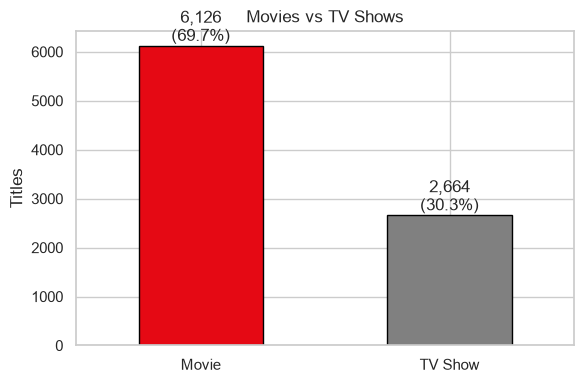

In [5]:
counts = df["type"].value_counts()
ax = counts.plot(kind="bar", color=[NETFLIX_RED, "#808080"], edgecolor="black", figsize=(6, 4))
for i, (label, v) in enumerate(counts.items()):
    ax.text(i, v, f"{v:,}\n({v/counts.sum():.1%})", ha="center", va="bottom")
plt.title("Movies vs TV Shows")
plt.ylabel("Titles")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. Catalogue Evolution Over Time

### Acquisition volume by year, segmented by content type
**How it helps:** Captures the acquisition ramp, the subsequent plateau, and the movie-weighted expansion.
**Business impact:** Provides a content-strategy timeline for benchmarking against competitor release cadence.

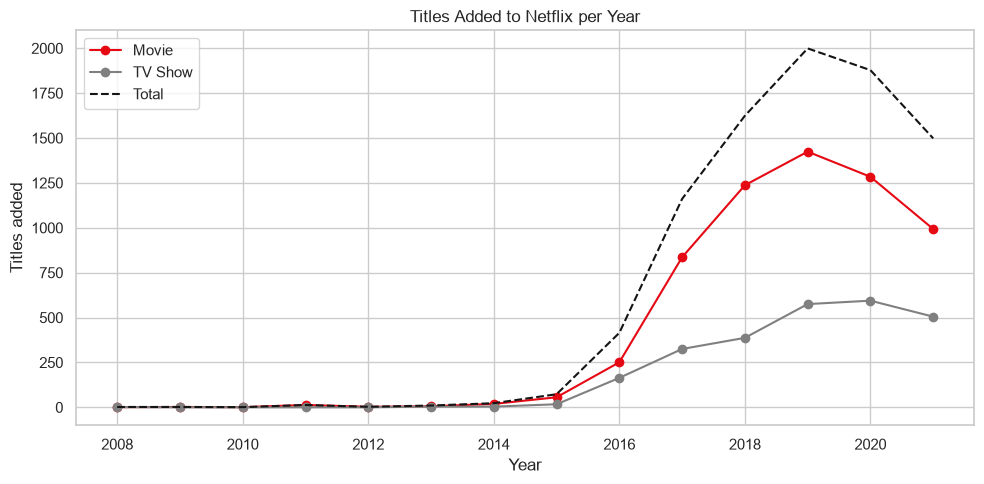

In [6]:
added = df.groupby(["year_added", "type"]).size().unstack(fill_value=0)

plt.figure(figsize=(10, 5))
for col, color in zip(added.columns, [NETFLIX_RED, "#808080"]):
    plt.plot(added.index, added[col], marker="o", label=col, color=color)
plt.plot(added.sum(axis=1), color=NETFLIX_BLACK, lw=1.5, ls="--", label="Total")
plt.title("Titles Added to Netflix per Year")
plt.ylabel("Titles added")
plt.xlabel("Year")
plt.legend()
plt.tight_layout()
plt.show()

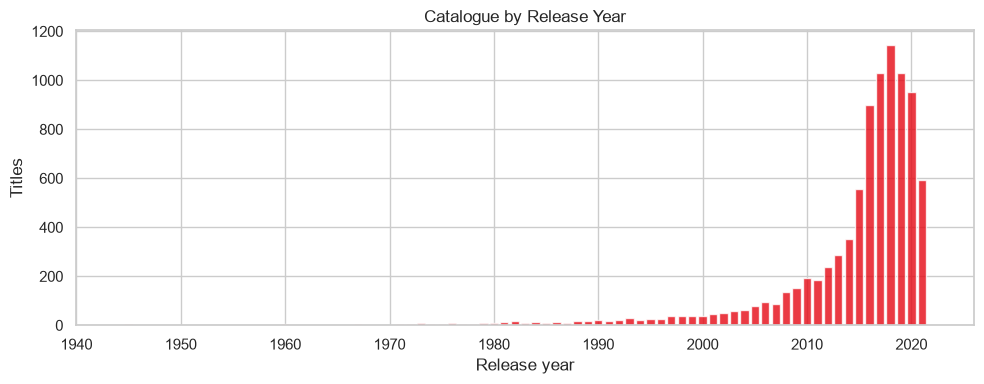

Median content age at time of adding: 1 years
Share released in last 5 yrs (vs year added): 75.8%


In [7]:
# Catalogue age profile derived from release year
old = df["release_year"].value_counts().sort_index()
plt.figure(figsize=(10, 4))
plt.bar(old.index, old.values, color=NETFLIX_RED, alpha=0.8)
plt.title("Catalogue by Release Year")
plt.ylabel("Titles")
plt.xlabel("Release year")
plt.xlim(1940, 2026)
plt.tight_layout()
plt.show()

age = df["year_added"] - df["release_year"]
print(f"Median content age at time of adding: {age.median():.0f} years")
print(f"Share released in last 5 yrs (vs year added): {(age <= 5).mean():.1%}")

## 4. Geographic Distribution

### Top 10 origin markets
**How it helps:** Origin-market concentration; unknown values retained and reported rather than silently discarded.

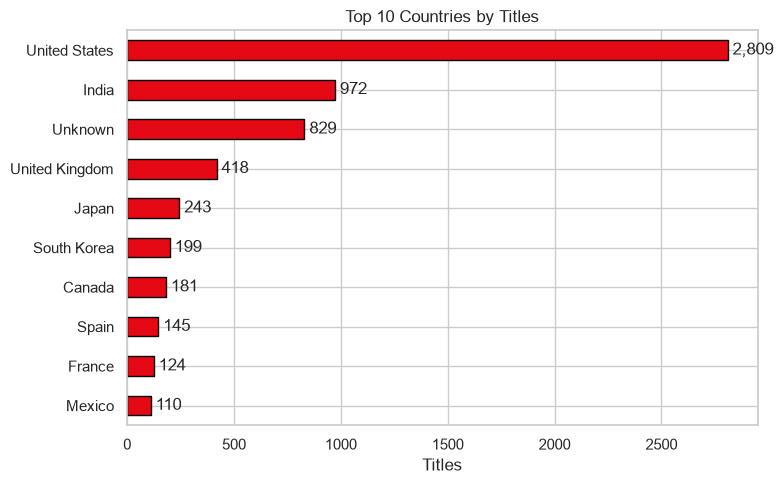

In [8]:
top_countries = df["country"].value_counts().head(10).sort_values()

plt.figure(figsize=(8, 5))
top_countries.plot(kind="barh", color=NETFLIX_RED, edgecolor="black")
plt.title("Top 10 Countries by Titles")
plt.xlabel("Titles")
plt.ylabel("")
for i, v in enumerate(top_countries):
    plt.text(v, i, f" {v:,}", va="center")
plt.tight_layout()
plt.show()

## 5. Content Ratings

### Content rating distribution

Horizontal bars are used here; pie charts with more than ~10 categories impair readability.

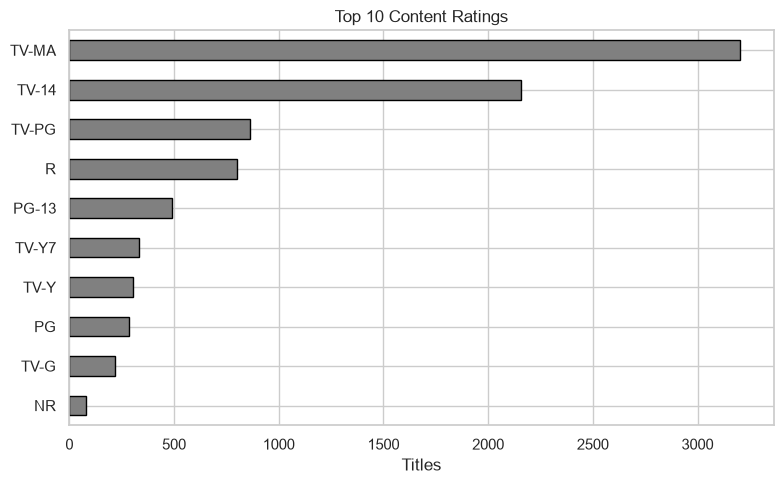

In [9]:
ratings = df["rating"].value_counts().head(10).sort_values()

plt.figure(figsize=(8, 5))
ratings.plot(kind="barh", color="#808080", edgecolor="black")
plt.title("Top 10 Content Ratings")
plt.xlabel("Titles")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 6. Genre Composition

`listed_in` is a multi-label field; it is exploded to obtain unbiased genre frequency counts.

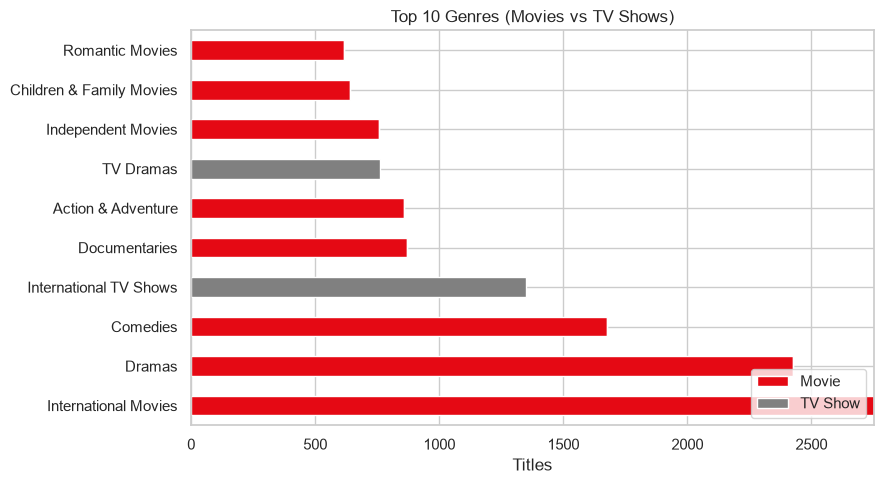

In [10]:
genres = (df.assign(genre=df["listed_in"].str.split(", "))
             .explode("genre")
             .groupby("genre")["type"]
             .value_counts()
             .unstack(fill_value=0))
genres["total"] = genres.sum(axis=1)
top_genres = genres.sort_values("total", ascending=False).head(10)

ax = top_genres[["Movie", "TV Show"]].plot(kind="barh", stacked=True, figsize=(9, 5),
                                           color=[NETFLIX_RED, "#808080"])
plt.title("Top 10 Genres (Movies vs TV Shows)")
plt.xlabel("Titles")
plt.ylabel("")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. Duration Profiles

Duration is dual-format (films expressed in minutes, series in seasons); parsed and analysed as separate populations.

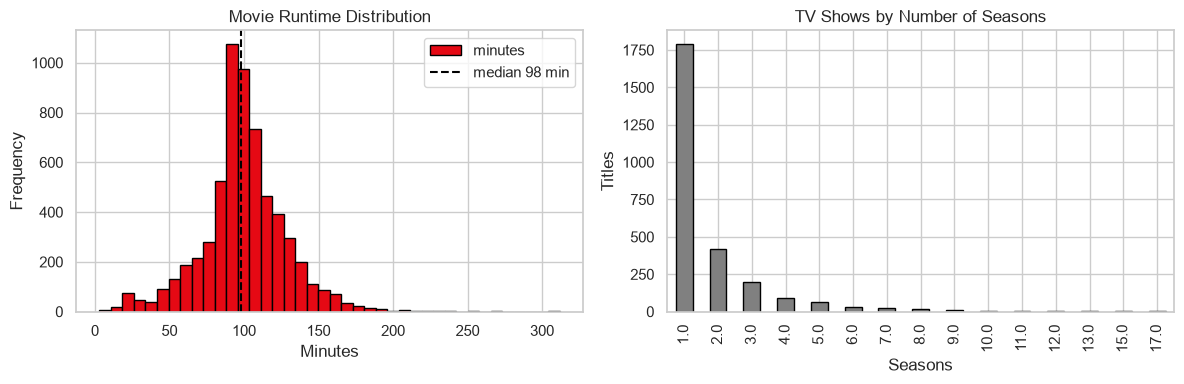

Median movie runtime : 98 min
Median show length   : 1 seasons


In [11]:
movies = df[df["type"] == "Movie"].copy()
shows = df[df["type"] == "TV Show"].copy()

movies["minutes"] = movies["duration"].str.extract(r"(\d+)").astype(float)
shows["seasons"] = shows["duration"].str.extract(r"(\d+)").astype(float)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

movies["minutes"].plot(kind="hist", bins=40, ax=axes[0], color=NETFLIX_RED, edgecolor="black")
axes[0].set_title("Movie Runtime Distribution")
axes[0].set_xlabel("Minutes")
axes[0].axvline(movies["minutes"].median(), color="black", ls="--", label=f"median {movies['minutes'].median():.0f} min")
axes[0].legend()

shows["seasons"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="#808080", edgecolor="black")
axes[1].set_title("TV Shows by Number of Seasons")
axes[1].set_xlabel("Seasons")
axes[1].set_ylabel("Titles")

plt.tight_layout()
plt.show()
print(f"Median movie runtime : {movies['minutes'].median():.0f} min")
print(f"Median show length   : {shows['seasons'].median():.0f} seasons")

## 8. Executive Summary

In [12]:
top_country = df.loc[df["country"] != "Unknown", "country"].value_counts()
print(f'''Titles kept after cleaning : {len(df):,} ({(before-len(df))/before:.1%} dropped)
Movies vs TV Shows         : {counts['Movie']:,} vs {counts['TV Show']:,} ({counts['Movie']/counts.sum():.0%} movies)
Peak adding year           : {added.sum(axis=1).idxmax():.0f} ({added.sum(axis=1).max():,} titles)
Top country (excl Unknown) : {top_country.index[0]} ({top_country.iloc[0]:,})
Median content age         : {age.median():.0f} years
Median movie runtime       : {movies['minutes'].median():.0f} min''')

Titles kept after cleaning : 8,790 (0.2% dropped)
Movies vs TV Shows         : 6,126 vs 2,664 (70% movies)
Peak adding year           : 2019 (1,999 titles)
Top country (excl Unknown) : United States (2,809)
Median content age         : 1 years
Median movie runtime       : 98 min


## 9. Recommended Next-Phase Analyses

1. **Collaboration network** — explode `cast` to identify recurring ensembles and top actors by title count.
2. **Natural-language analysis** — TF-IDF and sentiment on `description`; topic clustering conditioned on genre.
3. **Regional preference analysis** — genre mix by origin market; runtime distributions by country.
4. **Renewal analysis** — seasons versus release year to test whether newer series exhibit different renewal patterns.
5. **Business-intelligence layer** — Streamlit/Power BI dashboard with type, year and country filters.